# AI-Powered Software Bug Severity Prediction System

**Software Persona | Artificial Intelligence Project**

## 1. Problem Definition

This project aims to predict the severity level of software bugs using machine learning.

The system analyzes bug reports to help software development teams prioritize issues and improve their bug management process.

**Problem Type:** Classification

**Target Variable:** Severity Label

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [53]:
df=pd.read_csv("/content/drive/MyDrive/software_bugs.csv")
df.head()

,Project,Bug ID,Severity Label,Resolution Status,Short Description
0,Bugzilla,322082,normal,FIXED,Clean up user selection SQL
1,Bugzilla,322412,trivial,FIXED,Typo in error message
2,Bugzilla,322315,normal,FIXED,If logged out $user->can_bless gives: Not an A...
3,Bugzilla,322244,trivial,FIXED,cookies are incorrectly detainted when logging...
4,Bugzilla,322212,critical,FIXED,DERIVE_GROUPS_TABLES_ALREADY_LOCKED is ignored...


In [54]:
df.shape

(88682, 5)

In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88682 entries, 0 to 88681
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Project            88682 non-null  object
 1   Bug ID             88682 non-null  int64 
 2   Severity Label     88682 non-null  object
 3   Resolution Status  88682 non-null  object
 4   Short Description  88682 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.4+ MB


In [56]:
df.describe()

,Bug ID
count,88682.000000
mean,465729.263278
std,199035.411756
min,122433.000000
25%,318964.750000
50%,458102.000000
75%,630730.500000
max,825526.000000


In [57]:
df.isnull().sum()

,0
Project,0
Bug ID,0
Severity Label,0
Resolution Status,0
Short Description,0


## 2. Dataset Overview

The dataset contains 88,682 software bug reports from the Eclipse Bugzilla system.

It consists of five columns:

- Project

- Bug ID

- Severity Label

- Resolution Status

- Short Description

The dataset contains four categorical/text columns and one numerical column.

The target variable is "Severity Label", which represents the severity level of each software bug.

### Initial Data Quality Check

- Total Records: 88,682

- Total Columns: 5

- Missing Values: 0

No missing values were detected in the dataset. Further data cleaning and preprocessing will be performed before model training.

In [58]:
df.duplicated().sum()

np.int64(0)

In [59]:
df["Severity Label"].unique()

array(['normal', 'trivial', 'critical', 'major', 'blocker', 'minor'],
      dtype=object)

In [60]:
df["Severity Label"].value_counts()

,count
Severity Label,
normal,72170
critical,5936
major,4573
minor,3125
trivial,2080
blocker,798


Severity Distribution Analysis

The dataset contains six severity categories: normal, critical, major, minor, trivial, and blocker.

The normal category represents approximately 81.4% of all bug reports, while blocker accounts for only 0.9%.

This indicates a significant class imbalance. Therefore, accuracy alone may not be sufficient to evaluate the model’s performance.

In [61]:
df["Project"].value_counts()

,count
Project,
Core,46916
Platform,13842
Firefox,11737
JDT,5891
CDT,4228
Thunderbird,3663
Bugzilla,2405


Project Distribution Analysis

The dataset contains bug reports from seven software projects.

Core has the highest number of bug reports (46,916), representing approximately 52.9% of the dataset.

Bugzilla has the lowest number of reports (2,405).

This distribution shows that some software projects are more heavily represented than others.

In [62]:
df["Resolution Status"].unique()

array(['FIXED'], dtype=object)

In [63]:
df["Resolution Status"].value_counts()

,count
Resolution Status,
FIXED,88682


Resolution Status Analysis

All 88,682 bug reports have the same resolution status: FIXED.

Since this column contains only one unique value, it does not provide useful information for predicting bug severity.

Therefore, Resolution Status will be excluded from the model’s input features.

In [64]:
df["Bug ID"].duplicated().sum()

np.int64(266)

In [65]:
df[df["Bug ID"].duplicated(keep=False)].head(10)

,Project,Bug ID,Severity Label,Resolution Status,Short Description
8,Bugzilla,323575,normal,FIXED,[PostgreSQL] sanitycheck.cgi?createmissinggrou...
30,Bugzilla,328063,normal,FIXED,Upgrading to 2.23 on PostgreSQL generates an e...
44,Bugzilla,329295,normal,FIXED,008filter fails if . is not in PATH
50,Bugzilla,329334,normal,FIXED,User::match_field() may redirect you outside y...
55,Bugzilla,330588,trivial,FIXED,missing newline in Search.pm
88,Bugzilla,329196,blocker,FIXED,"Release/News Announcement for Bugzilla 2.20.2,..."
92,Bugzilla,335999,normal,FIXED,Remove documentation specific to MySQL 3.x
94,Bugzilla,337026,blocker,FIXED,Users with no privs cannot edit bugs anymore (...
95,Bugzilla,337209,trivial,FIXED,Missing whitespaces in the 'fieldvalue_still_h...
102,Bugzilla,337701,normal,FIXED,012throwables.t doesn't recognize that certain...


In [66]:
df[df["Bug ID"].duplicated(keep=False)].sort_values("Bug ID").head(10)

,Project,Bug ID,Severity Label,Resolution Status,Short Description
6130,CDT,322051,normal,FIXED,nested scoped variables visible on line after ...
7464,Core,322051,normal,FIXED,[BEOS] Dividing and restructuring nsWindow-code
6633,Core,322052,normal,FIXED,Fix document handling in nsObjectFrame.cpp
6131,CDT,322052,normal,FIXED,edc JUnit test TestLocalScopes1 relying on inc...
54361,Firefox,322169,normal,FIXED,Clear Private Data does not clear JS Console
6232,CDT,322169,normal,FIXED,New Makefile Project with Existing Code wizard...
6641,Core,322293,normal,FIXED,pull cross-commit by default
84615,Platform,322293,normal,FIXED,NPE when select Hyperlink from MultipleHyperli...
84063,Platform,322319,normal,FIXED,3.7 M1 build has wrong title for logs
6635,Core,322319,normal,FIXED,WMF Files opened with Windows Media Player Plugin


Duplicate Records Analysis

No completely duplicated rows were found in the dataset.

However, 266 repeated Bug ID values were identified. Further investigation showed that the same Bug ID can appear in different projects with different bug descriptions.

Therefore, these records were retained to avoid losing valid information.

In [67]:
Y=df["Severity Label"]
X=df[["Project","Short Description"]]

In [68]:
X.head()

,Project,Short Description
0,Bugzilla,Clean up user selection SQL
1,Bugzilla,Typo in error message
2,Bugzilla,If logged out $user->can_bless gives: Not an A...
3,Bugzilla,cookies are incorrectly detainted when logging...
4,Bugzilla,DERIVE_GROUPS_TABLES_ALREADY_LOCKED is ignored...


## 3. Data Cleaning and Feature Selection

Missing Values:
The dataset contains no missing values.

Duplicate Records:
No completely duplicated rows were found. Although 266 repeated Bug ID values were detected, these records belong to different projects and contain different bug descriptions. Therefore, no records were removed.

Class Distribution:
The dataset contains six severity categories. The normal category represents approximately 81.4% of all reports, indicating significant class imbalance.

Feature Selection:
The following columns were selected as input features:

* Project
* Short Description

The target variable is Severity Label.

Bug ID was excluded because it is an identifier. Resolution Status was excluded because all records have the same value (FIXED).

Final Dataset:
The dataset contains 88,682 records, with two selected input features and one target variable.

In [69]:
df["Severity Label"].value_counts(normalize=True)*100

,proportion
Severity Label,
normal,81.380663
critical,6.693579
major,5.156627
minor,3.523827
trivial,2.345459
blocker,0.899844


In [70]:
df["Project"].value_counts(normalize=True)*100

,proportion
Project,
Core,52.903633
Platform,15.608579
Firefox,13.234929
JDT,6.642836
CDT,4.767597
Thunderbird,4.130489
Bugzilla,2.711937


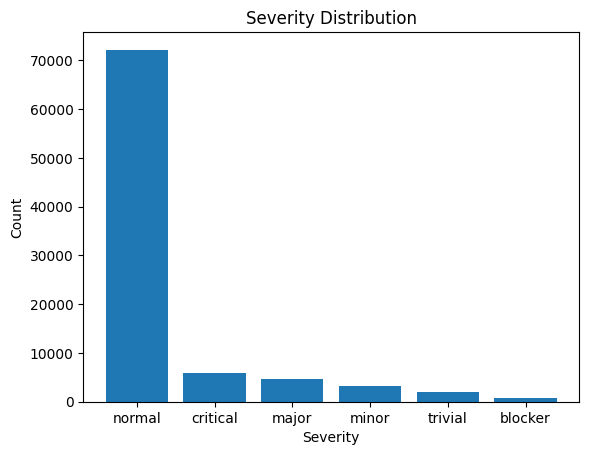

In [71]:
severity_counts=df["Severity Label"].value_counts()
plt.bar(severity_counts.index,severity_counts.values)
plt.title("Severity Distribution")
plt.xlabel("Severity")
plt.ylabel("Count")
plt.show()

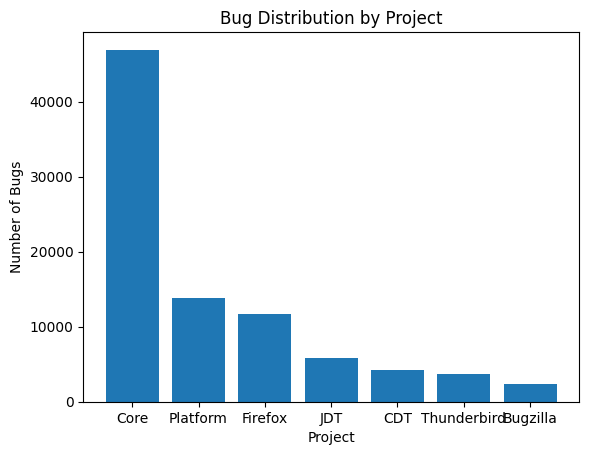

In [72]:
projects_counts=df["Project"].value_counts()
plt.bar(projects_counts.index,projects_counts.values)
plt.title("Bug Distribution by Project")
plt.xlabel("Project")
plt.ylabel("Number of Bugs")
plt.show()

In [73]:
severity_by_project=pd.crosstab(df["Project"],df["Severity Label"])
severity_by_project

Severity Label,blocker,critical,major,minor,normal,trivial
Project,,,,,,
Bugzilla,244,96,219,310,1366,170
CDT,38,81,268,192,3580,69
Core,243,4960,1805,1116,38184,608
Firefox,69,222,548,442,10058,398
JDT,45,110,396,360,4740,240
Platform,132,353,1097,520,11277,463
Thunderbird,27,114,240,185,2965,132


In [74]:
project_severity=df.groupby("Project")["Severity Label"].value_counts().unstack(fill_value=0)

print(project_severity)

Severity Label  blocker  critical  major  minor  normal  trivial
Project                                                         
Bugzilla            244        96    219    310    1366      170
CDT                  38        81    268    192    3580       69
Core                243      4960   1805   1116   38184      608
Firefox              69       222    548    442   10058      398
JDT                  45       110    396    360    4740      240
Platform            132       353   1097    520   11277      463
Thunderbird          27       114    240    185    2965      132


## 4. Exploratory Data Analysis (EDA)

Key Findings:

1. Class Imbalance: The normal severity category accounts for approximately 81.38% of all bug reports, indicating a significant class imbalance.
2. Project Distribution: Core represents approximately 52.90% of the dataset, making it the largest project in terms of bug reports.
3. Critical Bugs: Core contains 4,960 critical bug reports, the highest number among all projects.
4. Blocker Bugs: Bugzilla has 244 blocker reports, the highest count among the seven projects.
5. Model Evaluation: Due to the imbalanced class distribution, accuracy alone may be misleading. Precision, recall, and F1-score should also be considered when evaluating the machine learning model.

## 5. Data Preprocessing and Feature Engineering

The dataset was split into 80% training and 20% testing data using stratified sampling.

- Training samples: 70,945
- Testing samples: 17,737

TF-IDF was applied to bug descriptions, generating 5,000 text features.

One-Hot Encoding was applied to project names, generating 7 categorical features.

The final feature matrix contains 5,007 features.

In [75]:
from sklearn.model_selection import train_test_split

In [76]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=42,stratify=Y)

In [77]:
print(X_train.shape)
print(X_test.shape)

(70945, 2)
(17737, 2)


In [78]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [79]:
tfidf=TfidfVectorizer(max_features=5000)
X_train_tfidf=tfidf.fit_transform(X_train["Short Description"])
X_test_tfidf=tfidf.transform(X_test["Short Description"])

In [80]:
print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(70945, 5000)
(17737, 5000)


In [81]:
from sklearn.preprocessing import OneHotEncoder

In [82]:
encoder=OneHotEncoder(handle_unknown="ignore")
X_train_encoded=encoder.fit_transform(X_train[["Project"]])
X_test_encoded=encoder.transform(X_test[["Project"]])

In [83]:
print(X_train_encoded.shape)
print(X_test_encoded.shape)

(70945, 7)
(17737, 7)


In [84]:
from scipy.sparse import hstack

In [85]:
X_train_final=hstack((X_train_tfidf,X_train_encoded))
X_test_final=hstack((X_test_tfidf,X_test_encoded))

In [86]:
print(X_train_final.shape )
print(X_test_final.shape)

(70945, 5007)
(17737, 5007)


## 6. Model Training and Evaluation

Logistic Regression was selected as the classification algorithm.

The model was trained using 70,945 bug reports and evaluated on 17,737 test samples.

### Original Model Results

- Accuracy: 84.16%
- Weighted F1-Score: 79.02%
- Macro F1-Score: 33.13%

Although the model achieved high accuracy, its performance on minority severity classes was limited due to class imbalance.

Therefore, a second model using balanced class weights was trained for comparison.

In [87]:
from sklearn.linear_model import LogisticRegression

In [88]:
model=LogisticRegression(max_iter=1000)
model.fit(X_train_final,Y_train)

LogisticRegression(max_iter=1000)

In [89]:
Y_pred=model.predict(X_test_final)
print(Y_pred[:10])
print(Y_test[:10])

['normal' 'normal' 'normal' 'normal' 'normal' 'normal' 'normal' 'normal'
 'normal' 'normal']
74806    normal
75620    normal
36950    normal
16681     major
29342    normal
25985    normal
37802    normal
22553    normal
87938    normal
21376    normal
Name: Severity Label, dtype: object


In [90]:
from sklearn.metrics import accuracy_score,classification_report,f1_score
accuracy=accuracy_score(Y_test,Y_pred)
f1=f1_score(Y_test,Y_pred,average="weighted")
print(accuracy)
print(f1)
print(classification_report(Y_test, Y_pred))

0.8416304899362914
0.7901637551963313
              precision    recall  f1-score   support

     blocker       0.82      0.23      0.36       160
    critical       0.75      0.55      0.63      1187
       major       0.35      0.01      0.02       915
       minor       0.73      0.02      0.03       625
      normal       0.85      0.98      0.91     14434
     trivial       0.29      0.01      0.02       416

    accuracy                           0.84     17737
   macro avg       0.63      0.30      0.33     17737
weighted avg       0.80      0.84      0.79     17737



In [91]:
balanced_model=LogisticRegression(max_iter=1000, class_weight="balanced")
balanced_model.fit(X_train_final,Y_train)
Y_pred_balanced=balanced_model.predict(X_test_final)
accuracy_balanced=accuracy_score(Y_test, Y_pred_balanced)
f1_balanced=f1_score(Y_test, Y_pred_balanced, average="macro")
print(accuracy_balanced)
print(f1_balanced)
print(classification_report(Y_test, Y_pred_balanced))

0.4712183571066133
0.3053151597738391
              precision    recall  f1-score   support

     blocker       0.09      0.51      0.15       160
    critical       0.49      0.75      0.59      1187
       major       0.12      0.41      0.19       915
       minor       0.08      0.33      0.13       625
      normal       0.93      0.46      0.61     14434
     trivial       0.09      0.52      0.16       416

    accuracy                           0.47     17737
   macro avg       0.30      0.49      0.31     17737
weighted avg       0.80      0.47      0.56     17737



## 7. Model Comparison

Two Logistic Regression models were evaluated:

| Metric | Original Model | Balanced Model |
|---|---|---|
| Accuracy | 84.16% | 47.12% |
| Macro F1-Score | 33.13% | 30.53% |

The original model achieved higher accuracy and Macro F1-score.

The balanced model improved recall for minority classes but produced more incorrect predictions overall.

**Final Model:** The original Logistic Regression model was selected because it achieved better overall accuracy and Macro F1-score.

**Limitation:** The selected model struggles to identify less frequent severity categories.

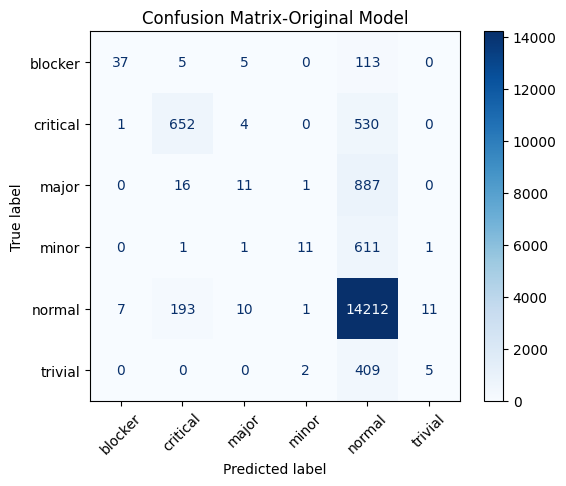

In [92]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(Y_test, Y_pred, labels=model.classes_)
display=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=model.classes_)
display.plot(cmap="Blues")
plt.title("Confusion Matrix-Original Model")
plt.xticks(rotation=45)
plt.show()

In [93]:
Y_train_pred=model.predict(X_train_final)
train_accuracy=accuracy_score(Y_train, Y_train_pred)
test_accuracy=accuracy_score(Y_test, Y_pred)
train_f1=f1_score(Y_train, Y_train_pred, average="macro")
test_f1 = f1_score(Y_test, Y_pred, average="macro")
print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)
print("Training Macro F1:", train_f1)
print("Testing Macro F1:", test_f1)

Training Accuracy: 0.8499400944393545
Testing Accuracy: 0.8416304899362914
Training Macro F1: 0.35967418415805336
Testing Macro F1: 0.3312837296943478


## 8. Confusion Matrix and Overfitting Analysis

### Confusion Matrix

The confusion matrix shows that the original model correctly predicts most normal bug reports but frequently misclassifies minority severity classes as normal.

This confirms that class imbalance affects the model's performance.

### Overfitting Analysis

| Metric | Training | Testing |
|---|---|---|
| Accuracy | 84.99% | 84.16% |
| Macro F1-Score | 35.97% | 33.13% |

The small difference between training and testing performance indicates that the model does not show significant overfitting.

However, the low Macro F1-score suggests that the model still struggles with minority classes.

In [94]:
new_bugs=pd.DataFrame({
    "Project": ["Core", "Firefox", "Platform"],
    "Short Description": [
    "Application crashes immediately after startup",
    "Browser freezes when opening multiple tabs",
    "Minor spelling mistake in settings menu"]})
print(new_bugs)

    Project                              Short Description
0      Core  Application crashes immediately after startup
1   Firefox     Browser freezes when opening multiple tabs
2  Platform        Minor spelling mistake in settings menu


In [95]:
new_tfidf=tfidf.transform(new_bugs["Short Description"])
new_encoded=encoder.transform(new_bugs[["Project"]])
new_features=hstack((new_tfidf,new_encoded))
print("Feature Shape:",new_features.shape)

Feature Shape: (3, 5007)


In [96]:
new_predictions=model.predict(new_features)
new_bugs["Predicted Severity"]=new_predictions
print(new_bugs.to_string(index=False))

 Project                             Short Description Predicted Severity
    Core Application crashes immediately after startup           critical
 Firefox    Browser freezes when opening multiple tabs             normal
Platform       Minor spelling mistake in settings menu             normal


## 9. Predictions on New Bug Reports

The trained model was tested using three new bug reports.

| Project | Bug Description | Predicted Severity |
|---|---|---|
| Core | Application crashes immediately after startup | critical |
| Firefox | Browser freezes when opening multiple tabs | normal |
| Platform | Minor spelling mistake in settings menu | normal |

The model successfully generated predictions for all three reports.

However, these predictions are not necessarily correct because the new reports do not have verified severity labels.

The results demonstrate how the system can classify new software bug descriptions.

In [97]:


print("AI Bug Severity Prediction System")

project=input("Enter project name: ")
description=input("Enter bug description: ")

user_bug=pd.DataFrame({
    "Project":[project],
    "Short Description":[description]
})

user_tfidf=tfidf.transform(user_bug["Short Description"])
user_encoded=encoder.transform(user_bug[["Project"]])
user_features=hstack((user_tfidf,user_encoded))

prediction=model.predict(user_features)

print("Predicted Severity:",prediction[0])

AI Bug Severity Prediction System
Enter project name: Core
Enter bug description: The application crashes when the user tries to save a file
Predicted Severity: normal


## 10. Interactive Prediction System

An interactive prediction system was developed using Python's input() function.

Users can enter a project name and a bug description. The system converts these inputs into numerical features using TF-IDF and One-Hot Encoding.

The trained Logistic Regression model then predicts the bug's severity level.

## 11. Conclusion

This project developed a machine learning system for predicting software bug severity.

### Key Achievements
- Analyzed 88,682 real-world bug reports.
- Applied TF-IDF and One-Hot Encoding.
- Trained and compared two Logistic Regression models.
- Achieved 84.16% accuracy with the original model.
- Developed an interactive bug severity prediction system.

### Limitations

The dataset is highly imbalanced, causing the model to perform better on the normal severity class than on less frequent categories.

### Future Improvements

Future work could explore additional machine learning algorithms, improved text preprocessing, and techniques for handling class imbalance.

Overall, the project demonstrates how machine learning can support software bug classification and prioritization.